# Explainable Fake News Detection System
## 1. Dataset Understanding

In [8]:
import pandas as pd
import numpy as np

In [9]:
df = pd.read_csv(
    r"C:\Users\Justina\OneDrive\Desktop\ML_project\explainable-fake-news-detection\data\WELFake_Dataset.csv"
)

In [10]:
df.head()


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [11]:
df.shape

(72134, 4)

In [12]:
df.columns

Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='str')

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  72134 non-null  int64
 1   title       71576 non-null  str  
 2   text        72095 non-null  str  
 3   label       72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 2.2 MB


In [14]:
df['label'].value_counts()

label
1    37106
0    35028
Name: count, dtype: int64

In [15]:
df['label'].unique()

array([1, 0])

In [16]:
df.isnull().sum()

Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

In [17]:
df.isnull().sum().sum()

np.int64(597)

In [18]:
(df.isnull().sum() / len(df)) * 100

Unnamed: 0    0.000000
title         0.773560
text          0.054066
label         0.000000
dtype: float64

In [19]:
df.duplicated().sum()

np.int64(0)

### 2. Data Cleaning and Preprocessing

In [20]:
df[['title', 'text', 'label']].duplicated().sum()

np.int64(8456)

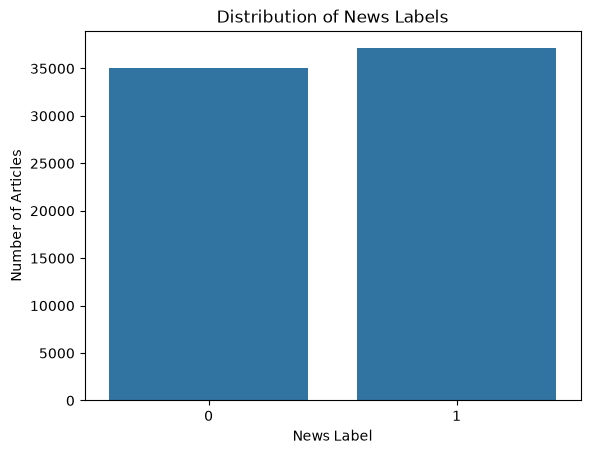

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='label')

plt.title("Distribution of News Labels")
plt.xlabel("News Label")
plt.ylabel("Number of Articles")

plt.show()

### Observation – Class Distribution

The dataset contains 72,134 news articles divided into two
categories: 0 and 1.

- Label 0: 35,028 articles (48.56%)
- Label 1: 37,106 articles (51.44%)

The dataset is relatively balanced, with a small difference
between the two classes. Therefore, no immediate class
balancing technique is required.

In [22]:
df[df['title'].isnull() & df['text'].notnull()].head()

,Unnamed: 0,title,text,label
1,1,NaN,Did they post their votes for Hillary already?,1
43,43,NaN,True. Hillary needs a distraction and what bet...,1
162,162,NaN,All eyes on Electoral delegates. The People kn...,1
185,185,NaN,Cool,1
269,269,NaN,A leading US senator: US Supporting War in Syr...,1


In [23]:
df[df['title'].isnull() & df['text'].isnull()]

,Unnamed: 0,title,text,label


In [24]:
df[df['title'].isnull() & df['text'].isnull()].shape

(0, 4)

In [25]:
df[df['text'].isnull() & df['title'].notnull()].head()

,Unnamed: 0,title,text,label
2457,2457,Après le succès de « Mariés au premier regard ...,NaN,1
3534,3534,Elections US : les premières estimations donne...,NaN,1
3709,3709,110% des Américains assurent qu’ils continuero...,NaN,1
5612,5612,Des millions d’Américains recherchent massivem...,NaN,1
6270,6270,Vladimir Poutine est élu 45e Président des Eta...,NaN,1


### 3. Handling Missing Values

In [26]:
df_clean = df.dropna(subset=['text'])

In [27]:
df_clean.isnull().sum()

Unnamed: 0      0
title         558
text            0
label           0
dtype: int64

In [28]:
df_clean.duplicated(subset=['title', 'text', 'label']).sum()

np.int64(8456)

### 4. Removing Duplicate Records

In [29]:
df_clean = df_clean.drop_duplicates(
    subset=['title', 'text', 'label']
)

In [30]:
print("Shape after removing duplicates:", df_clean.shape)

print(
    "Remaining duplicates:",
    df_clean.duplicated(subset=['title', 'text', 'label']).sum()
)

Shape after removing duplicates: (63639, 4)
Remaining duplicates: 0


In [31]:
df_clean = df_clean.drop(columns=['Unnamed: 0'])

In [32]:
df_clean.columns

Index(['title', 'text', 'label'], dtype='str')

In [33]:
df_clean['title'].fillna('')

0        LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1                                                         
2        UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3        Bobby Jindal, raised Hindu, uses story of Chri...
4        SATAN 2: Russia unvelis an image of its terrif...
                               ...                        
72127    WIKILEAKS EMAIL SHOWS CLINTON FOUNDATION FUNDS...
72129    Russians steal research on Trump in hack of U....
72130     WATCH: Giuliani Demands That Democrats Apolog...
72131    Migrants Refuse To Leave Train At Refugee Camp...
72132    Trump tussle gives unpopular Mexican leader mu...
Name: title, Length: 63639, dtype: str

### 5. Creating Combined Text Column

In [34]:
df_clean['content'] = (
    df_clean['title'].fillna('') + ' ' +
    df_clean['text'].fillna('')
)

In [35]:
df_clean[['title', 'text', 'content']].head()

,title,text,content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1,NaN,Did they post their votes for Hillary already?,Did they post their votes for Hillary already?
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,"Bobby Jindal, raised Hindu, uses story of Chri..."
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",SATAN 2: Russia unvelis an image of its terrif...


In [36]:
df_clean['content'].isnull().sum()

np.int64(0)

### 6. Text Cleaning

In [37]:
df_clean['content'] = df_clean['content'].str.lower()

In [38]:
import re

In [39]:
df_clean['content'] = df_clean['content'].apply(
    lambda x: re.sub(r'[^\w\s]', '', x)
)

In [40]:
df_clean['content'] = df_clean['content'].apply(
    lambda x: re.sub(r'https?://\S+|www\.\S+', '', x)
)

In [41]:
df_clean['content'] = df_clean['content'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

In [42]:
print(df_clean['content'].iloc[0])

law enforcement on high alert following threats against cops and whites on 911by blacklivesmatter and fyf911 terrorists video no comment is expected from barack obama members of the fyf911 or fukyoflag and blacklivesmatter movements called for the lynching and hanging of white people and cops they encouraged others on a radio show tuesday night to turn the tide and kill white people and cops to send a message about the killing of black people in americaone of the fyoflag organizers is called sunshine she has a radio blog show hosted from texas called sunshine s fing opinion radio show a snapshot of her fyf911 lolatwhitefear twitter page at 953 pm shows that she was urging supporters to call now fyf911 tonight we continue to dismantle the illusion of white below is a snapshot twitter radio call invite fyf911the radio show aired at 1000 pm eastern standard timeduring the show callers clearly call for lynching and killing of white peoplea 239 minute clip from the radio show can be heard h

### 7. Stop-Word Removal Using spaCy

In [43]:
import spacy
nlp = spacy.load('en_core_web_md')

In [44]:
stop_words=nlp.Defaults.stop_words

In [45]:
print(len(stop_words))

326


In [46]:
nlp.vocab['between'].is_stop

True

In [47]:
for word in ["the", "is", "not", "no", "never"]:
    print(word, nlp.vocab[word].is_stop)

the True
is True
not True
no True
never True


In [48]:
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("never")

In [49]:
filtered_texts = []

batch_size = 500

for i in range(0, len(df_clean), batch_size):

    batch = df_clean['content'].iloc[i:i + batch_size].fillna('').astype(str)

    docs = nlp.tokenizer.pipe(batch, batch_size=batch_size)

    for doc in docs:
        filtered_texts.append(
            ' '.join(
                token.text for token in doc
                if token.text.lower() not in stop_words
            )
        )

    print(f"Processed {min(i + batch_size, len(df_clean))} / {len(df_clean)}")

df_clean['content_no_stopwords'] = filtered_texts

print("Stop-word removal completed!")

Processed 500 / 63639
Processed 1000 / 63639
Processed 1500 / 63639
Processed 2000 / 63639
Processed 2500 / 63639
Processed 3000 / 63639
Processed 3500 / 63639
Processed 4000 / 63639
Processed 4500 / 63639
Processed 5000 / 63639
Processed 5500 / 63639
Processed 6000 / 63639
Processed 6500 / 63639
Processed 7000 / 63639
Processed 7500 / 63639
Processed 8000 / 63639
Processed 8500 / 63639
Processed 9000 / 63639
Processed 9500 / 63639
Processed 10000 / 63639
Processed 10500 / 63639
Processed 11000 / 63639
Processed 11500 / 63639
Processed 12000 / 63639
Processed 12500 / 63639
Processed 13000 / 63639
Processed 13500 / 63639
Processed 14000 / 63639
Processed 14500 / 63639
Processed 15000 / 63639
Processed 15500 / 63639
Processed 16000 / 63639
Processed 16500 / 63639
Processed 17000 / 63639
Processed 17500 / 63639
Processed 18000 / 63639
Processed 18500 / 63639
Processed 19000 / 63639
Processed 19500 / 63639
Processed 20000 / 63639
Processed 20500 / 63639
Processed 21000 / 63639
Processed 21

### 8. TF-IDF Vectorization

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [51]:
tfidf = TfidfVectorizer(max_features=5000)

In [52]:
X = tfidf.fit_transform(df_clean['content_no_stopwords'])

In [53]:
y = df_clean['label']

In [54]:
print(X.shape)

(63639, 5000)


### Model Training – Train-Test Split

In [55]:
from sklearn.model_selection import train_test_split

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [57]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(50911, 5000)
(12728, 5000)
(50911,)
(12728,)


### 10. Logistic Regression Model Training

In [58]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### 11. Model Prediction

In [59]:
y_pred = model.predict(X_test)

In [60]:
print(y_pred[:10])

[1 0 0 0 0 0 1 1 0 0]


### 12. Model Evaluation

In [61]:
from sklearn.metrics import accuracy_score

In [62]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.9508956631049654


In [63]:
from sklearn.metrics import classification_report

In [64]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.95      0.96      6958
           1       0.95      0.95      0.95      5770

    accuracy                           0.95     12728
   macro avg       0.95      0.95      0.95     12728
weighted avg       0.95      0.95      0.95     12728



In [65]:
from sklearn.metrics import confusion_matrix

In [66]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[6644  314]
 [ 311 5459]]


In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

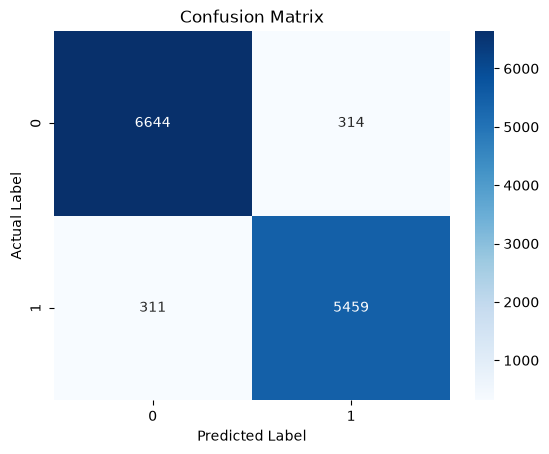

In [68]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

### 13. LIME Explainability

In [69]:
%pip install lime

Note: you may need to restart the kernel to use updated packages.


In [70]:
from lime.lime_text import LimeTextExplainer

In [71]:
explainer = LimeTextExplainer(class_names=['Fake', 'Real'])

### 14. LIME Prediction Function

In [76]:
def predict_probability(text):
    text_tfidf = tfidf.transform(text)

    return model.predict_proba(text_tfidf)

In [93]:
sample_text = df_clean['content_no_stopwords'].iloc[1]

### 15. News Prediction with Probability

In [81]:
probability = predict_probability([sample_text])

if probability[0][0] > probability[0][1]:
    print("Prediction: Fake News")
else:
    print("Prediction: Real News")

print("Fake News Probability:", round(probability[0][0] * 100, 2), "%")
print("Real News Probability:", round(probability[0][1] * 100, 2), "%")



Prediction: Fake News
Fake News Probability: 63.67 %
Real News Probability: 36.33 %


### 16. LIME Explanation

In [82]:
explanation = explainer.explain_instance(
    sample_text,
    predict_probability,
    num_features=10
)

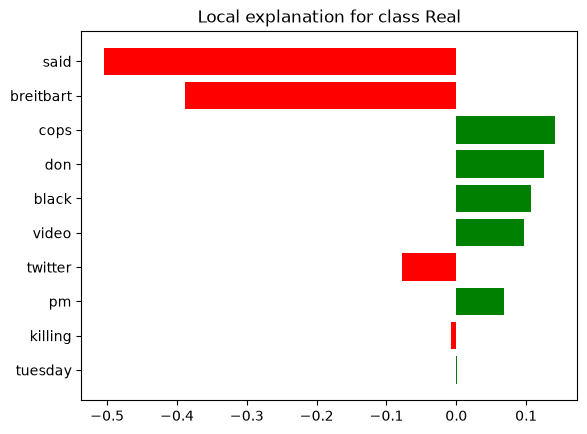

In [87]:
explanation.as_pyplot_figure()
plt.show()

In [90]:
explanation = explainer.explain_instance(
    sample_text,
    predict_probability,
    num_features=10
)

In [91]:
print(explanation.as_list())

[(np.str_('hillary'), 0.05151687692392534), (np.str_('post'), 0.03474697278828714), (np.str_('votes'), 0.007554447895947495)]
